# Drying: a tray dryer and a rotary dryer

`difflow.units.dryer` has the drying library (moisture bookkeeping, GAB/BET/tabulated equilibrium isotherms,
the constant drying rate, and the drying time across the constant- and falling-rate periods with a **smooth**
switch at the critical moisture) and the `Dryer` unit (batch tray or continuous countercurrent/cocurrent) with
psychrometric air balances.

**Everything numerical below is an illustration with invented inputs.** The Geankoplis Ch. 9 and McCabe Ch. 24
drying examples were not reproduced (their numbers could not be recalled with confidence), the GAB parameters are
placeholders and not those of a real material, and the tray correlation $h = 0.0204\,G^{0.8}$ is typed from
memory and unverified. What *is* checked (in `tests/test_dryer.py`) is the closed-form drying time against a
numerical $\int dX/R$, the smooth switch converging to the exact piecewise answer, the air balances against
the streams, and the gradients.

In [1]:
import math
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
from difflow import (Dryer, DryerParams, drying_time, drying_periods, drying_rate_curve, constant_drying_rate,
                     equilibrium_moisture, water_activity, heat_transfer_coefficient_tray)
from difflow.psychrometrics import air_stream_from_state, state, mix_air, MW_WATER
K = 273.15

## 1. Moisture, isotherm and the drying curve

A GAB isotherm gives the equilibrium moisture in the drying air; `water_activity` inverts it. Then a drying-rate
curve with a constant-rate period down to $X_c$ and a falling rate (linear in the free moisture) below.

a_w  : [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]
X_eq : [0.     0.0368 0.0567 0.0727 0.0888 0.1072 0.1303 0.1618 0.2089 0.289 ]
round trip a_w: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9]


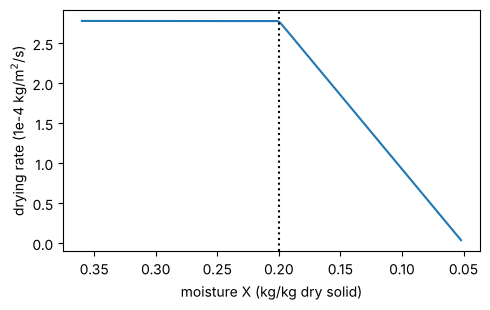

In [2]:
gab = {"X_m": 0.07, "C": 10.0, "K": 0.85}          # illustrative, NOT a real material
aw = np.linspace(0.0, 0.9, 10)
X_eq = equilibrium_moisture(aw, 300.0, "gab", gab)
print("a_w  :", np.round(aw, 2))
print("X_eq :", np.round(np.asarray(X_eq), 4))
print("round trip a_w:", np.round(np.asarray(water_activity(X_eq, 300.0, "gab", gab)), 6))

X1, X2, Xc, Xe = 0.35, 0.10, 0.20, 0.05
Rc, LsA = 2.78e-4, 25.0                              # kg/m^2/s, kg dry solid / m^2
X = np.linspace(0.36, Xe + 0.002, 400)
plt.figure(figsize=(5, 3.2))
plt.plot(X, 1e4 * np.asarray(drying_rate_curve(X, Xc, Xe, Rc)))
plt.axvline(Xc, ls=":", c="k"); plt.gca().invert_xaxis()
plt.xlabel("moisture X (kg/kg dry solid)"); plt.ylabel("drying rate (1e-4 kg/m$^2$/s)")
plt.tight_layout(); plt.show()

## 2. Drying time and the smooth switch

The time is one smooth expression, so the gradient with respect to the critical moisture exists even when
$X_c$ moves through $X_1$ or $X_2$. The default `sharpness` is 200; larger values recover the piecewise answer.

In [3]:
def exact(X1, X2, Xc, Xe, Rc, LsA):
    t = 0.0
    xa = min(X1, Xc)
    if X1 > Xc:
        t += LsA * (X1 - max(X2, Xc)) / Rc
    if X2 < xa:
        t += LsA * (Xc - Xe) / Rc * math.log((xa - Xe) / (X2 - Xe))
    return t

t_c, t_f = drying_periods(X1, X2, Xc, Xe, Rc, LsA)
print(f"constant period {float(t_c)/3600:.3f} h, falling period {float(t_f)/3600:.3f} h, "
      f"total {float(drying_time(X1, X2, Xc, Xe, Rc, LsA))/3600:.4f} h (exact {exact(X1, X2, Xc, Xe, Rc, LsA)/3600:.4f} h)")

# the worst case, X1 exactly at X_c, against the sharpness
for s in (20, 100, 200, 1000, 10000):
    t = float(drying_time(Xc, X2, Xc, Xe, Rc, LsA, sharpness=s))
    print(f"sharpness {s:6d}: error {abs(t - exact(Xc, X2, Xc, Xe, Rc, LsA)) / exact(Xc, X2, Xc, Xe, Rc, LsA):.2e}")

g = jax.grad(drying_time, argnums=(0, 2, 4, 5))(X1, X2, Xc, Xe, Rc, LsA)
print("d t/d(X1, Xc, Rc, Ls/A) [h per unit]:", [f"{float(v)/3600:.4g}" for v in g])

constant period 3.747 h, falling period 4.117 h, total 7.8635 h (exact 7.8635 h)
sharpness     20: error 5.59e-04
sharpness    100: error 2.20e-05
sharpness    200: error 5.48e-06
sharpness   1000: error 2.19e-07
sharpness  10000: error 2.19e-09


d t/d(X1, Xc, Rc, Ls/A) [h per unit]: ['24.98', '27.44', '-2.829e+04', '0.3145']


## 3. A batch tray dryer

Air at 70 C and 1 % humidity (humidity ratio 0.01) flows over 12.5 kg of granules on 0.5 m$^2$ of tray at a mass
velocity of 1 kg/m$^2$/s. The constant rate comes from $h(T - T_{wb})/\lambda$ with the wet bulb from
`difflow.psychrometrics` and $h$ from the tray correlation (unverified).

In [4]:
wet = {"F_solid": 0.01, "F_H2O": 0.01 * 0.35 / MW_WATER, "T": 295.0, "P": 101325.0}   # 0.01 kg/s throughput, X = 0.35
air = air_stream_from_state(state(T=70.0 + K, W=0.01), 0.5)                            # 0.5 kg/s dry air
tray = Dryer(DryerParams(mode="batch", X_c=0.20, X_eq=0.05, product_moisture=0.10,
                         air_mass_velocity=1.0, load=12.5, area=0.5, max_solids_T=330.0))
dry, exhaust, info = tray(wet, air)
print(f"h = {float(heat_transfer_coefficient_tray(1.0)):.1f} W/m2/K, R_c = {float(info['R_c']):.3e} kg/m2/s")
print(f"drying time {float(info['drying_time'])/3600:.2f} h  (constant {float(info['t_constant'])/3600:.2f} h, "
      f"falling {float(info['t_falling'])/3600:.2f} h)")
print(f"product {float(info['T_solids_out'])-K:.1f} C (margin to the limit {float(info['solids_T_margin']):.1f} K); "
      f"exhaust {float(info['T_air_out'])-K:.1f} C, W {float(info['W_out']):.5f}; "
      f"humidity rise {float(info['air_humidity_rise']):.1e} (small, as assumed)")
print(f"tray area for the 0.01 kg/s throughput: {float(info['area_required']):.0f} m^2")

h = 14.3 W/m2/K, R_c = 2.359e-04 kg/m2/s
drying time 9.27 h  (constant 4.42 h, falling 4.85 h)
product 56.6 C (margin to the limit 0.2 K); exhaust 69.5 C, W 0.01019; humidity rise 1.9e-04 (small, as assumed)
tray area for the 0.01 kg/s throughput: 13 m^2


Drying time against inlet temperature and air velocity, with the exact gradient.

In [5]:
def t_dry(T, G):
    d = Dryer(DryerParams(mode="batch", X_c=0.20, X_eq=0.05, product_moisture=0.10,
                          air_mass_velocity=G, load=12.5, area=0.5))
    return d(wet, air_stream_from_state(state(T=T, W=0.01), 0.5))[2]["drying_time"]
for T in (50.0, 70.0, 90.0):
    print(f"T = {T:.0f} C: " + ", ".join(f"G={G}: {float(t_dry(T + K, G))/3600:5.1f} h" for G in (0.5, 1.0, 2.0)))
dT, dG = jax.grad(t_dry, argnums=(0, 1))(70.0 + K, 1.0)
print(f"at 70 C, G = 1: d t/dT = {float(dT)/3600:.3f} h/K, d t/dG = {float(dG)/3600:.2f} h per kg/m2/s")

T = 50 C: G=0.5:  26.3 h, G=1.0:  15.1 h, G=2.0:   8.7 h


T = 70 C: G=0.5:  16.1 h, G=1.0:   9.3 h, G=2.0:   5.3 h


T = 90 C: G=0.5:  11.5 h, G=1.0:   6.6 h, G=2.0:   3.8 h


at 70 C, G = 1: d t/dT = -0.184 h/K, d t/dG = -7.41 h per kg/m2/s


## 4. A continuous (rotary) dryer: countercurrent against cocurrent

0.5 kg/s of dry solid at moisture 0.30 is dried to 0.05 by 10 kg/s of air at 100 C. The solids leave at
$T_a - (T_a - T_{wb})R(X_{out})/R_c$ in the air at their exit end, which is the hot inlet air for countercurrent
flow, so the countercurrent product is hotter (and overshoots the 67 C limit here), while the cocurrent solids meet
the cold, humid exhaust air.

In [6]:
air = air_stream_from_state(state(T=100.0 + K, W=0.01), 10.0)
wet = {"F_solid": 0.5, "F_H2O": 0.5 * 0.30 / MW_WATER, "T": 300.0, "P": 101325.0}
for flow in ("countercurrent", "cocurrent"):
    d = Dryer(DryerParams(mode="continuous", flow=flow, X_c=0.15, X_eq=0.02, product_moisture=0.05,
                          h=60.0, solids_per_area=10.0, max_solids_T=340.0, entrainment=0.02))
    dry, exhaust, info = d(wet, air)
    print(f"{flow:15s} exhaust {float(info['T_air_out'])-K:5.1f} C (dew-point margin {float(info['dew_point_margin']):4.1f} K), "
          f"product {float(info['T_solids_out'])-K:5.1f} C (margin {float(info['solids_T_margin']):6.1f} K), "
          f"residence {float(info['residence_time_required'])/60:4.0f} min, {float(info['energy_per_kg'])/1e6:.2f} MJ/kg water, "
          f"efficiency {float(info['thermal_efficiency']):.2f}")
    print(f"{'':15s} balances: water {float(info['water_balance_residual']):.1e} kg/s, energy {float(info['energy_balance_residual']):.1e} W; "
          f"fines {float(info['fines']['F_solid']):.3f} kg/s dry")

countercurrent  exhaust  64.5 C (dew-point margin 37.7 K), product  85.1 C (margin  -18.2 K), residence   76 min, 6.56 MJ/kg water, efficiency 0.37
                balances: water -2.8e-17 kg/s, energy 2.3e-10 W; fines 0.010 kg/s dry


cocurrent       exhaust  66.6 C (dew-point margin 39.8 K), product  59.3 C (margin    7.5 K), residence   35 min, 6.56 MJ/kg water, efficiency 0.37
                balances: water -2.8e-17 kg/s, energy 0.0e+00 W; fines 0.010 kg/s dry


Recirculating some exhaust air (a mixing point on the psychrometric chart) raises the inlet humidity and cuts the
fresh-air heating; `mix_air` gives the inlet state, and the dryer's dew-point margin shows how far it can go.

This is one pass, not a converged recycle loop: the recycle state is taken from the dryer run without recycle.

In [7]:
fresh = state(T=20.0 + K, W=0.008)
for frac in (0.0, 0.3, 0.6):
    _, ex, info0 = Dryer(DryerParams(mode="continuous", flow="countercurrent", X_c=0.15, X_eq=0.02,
                                     product_moisture=0.05, h=60.0))(wet, air)
    recycle = state(T=float(info0["T_air_out"]), W=float(info0["W_out"]))
    mixed = mix_air([fresh, recycle], [(1 - frac) * 10.0, frac * 10.0])
    # heat the mixed air to 100 C at constant humidity, run the dryer
    hot = air_stream_from_state(state(T=100.0 + K, W=mixed["W"]), 10.0)
    _, _, info = Dryer(DryerParams(mode="continuous", flow="countercurrent", X_c=0.15, X_eq=0.02,
                                   product_moisture=0.05, h=60.0))(wet, hot)
    print(f"recycle {frac:.0%}: inlet W {float(mixed['W']):.4f}, exhaust {float(info['T_air_out'])-K:5.1f} C, "
          f"dew-point margin {float(info['dew_point_margin']):5.1f} K")

recycle 0%: inlet W 0.0080, exhaust  64.4 C, dew-point margin  39.1 K


recycle 30%: inlet W 0.0123, exhaust  64.7 C, dew-point margin  36.2 K


recycle 60%: inlet W 0.0167, exhaust  64.9 C, dew-point margin  33.7 K


## 5. Design with gradients

With the dryer size fixed (a residence time of 4000 s) the air flow that meets the product spec falls as the inlet
air gets hotter, so the energy per kg of water falls too, until the product temperature reaches its limit
(`max_solids_T`, here 77 C). The limit is a soft constraint in the objective and the optimum is found with the exact
gradient (through the implicit air-flow solve).

In [8]:
from difflow.staged import _solve_monotone
T_max, t_avail = 350.0, 4000.0
dryer = Dryer(DryerParams(mode="continuous", flow="countercurrent", X_c=0.15, X_eq=0.02, product_moisture=0.05,
                          h=60.0, solids_per_area=10.0, max_solids_T=T_max))
run = lambda T, G: dryer(wet, air_stream_from_state(state(T=T, W=0.01), G))[2]
air_flow = lambda T: _solve_monotone(lambda G: run(T, G)["residence_time_required"] - t_avail, 4.0, 60.0)
def objective(T):
    info = run(T, air_flow(T))
    return info["energy_per_kg"] / 1e6 + 5.0 * jax.nn.softplus((info["T_solids_out"] - T_max) / 0.1)
grad = jax.jit(jax.grad(objective))
for T in (360.0, 380.0, 400.0):
    G = air_flow(T); i = run(T, G)
    print(f"T_in {T-K:.0f} C: air {float(G):5.1f} kg/s, {float(i['energy_per_kg'])/1e6:.2f} MJ/kg, product {float(i['T_solids_out'])-K:.0f} C")
lo, hi = 350.0, 420.0
for _ in range(25):
    T = 0.5 * (lo + hi)
    lo, hi = (T, hi) if grad(T) < 0.0 else (lo, T)
T = 0.5 * (lo + hi); G = air_flow(T); i = run(T, G)
print(f"optimum: T_in = {T-K:.1f} C, air {float(G):.1f} kg/s, product {float(i['T_solids_out'])-K:.1f} C "
      f"(limit {T_max-K:.0f} C), {float(i['energy_per_kg'])/1e6:.2f} MJ/kg water")

T_in 87 C: air  17.5 kg/s, 9.60 MJ/kg, product 74 C


T_in 107 C: air   9.7 kg/s, 6.93 MJ/kg, product 91 C


T_in 127 C: air   6.8 kg/s, 5.99 MJ/kg, product 107 C


optimum: T_in = 89.2 C, air 16.0 kg/s, product 76.3 C (limit 77 C), 9.07 MJ/kg water
